# Laboratory Work 2. Digital Image Processing

This laboratory work explores various types of digital image processing.

Objective of the laboratory work:

# 1. OpenCV
The opencv-python package is one of the most convenient ways to work with images. OpenCV is an implementation of a library of computer vision, image processing, and general-purpose numerical algorithms. opencv-python is a wrapper for the original OpenCV library, written in C++, which makes it equally fast. All opencv-python array structures (hereafter simply referred to as OpenCV) can be converted to and from NumPy arrays. This also makes integration with other libraries that use NumPy, such as SciPy and Matplotlib, easier.

OpenCV offers a wide range of algorithms and consists of the following modules:
- core -- core functionality, including basic data structures, computations (mathematical functions, random number generators), linear algebra, etc.;
- imgproc -- image processing (filtering, geometric transformations, color space conversion, etc.);
- imgcodecs -- reading and writing image files;
- videoio -- reading and writing video or image sequences;
- highgui -- creating a simple user interface and handling mouse and keyboard events;
- video -- video processing;
- calib3d -- camera calibration and 3D reconstruction;
- features2d -- working with feature points;
- objdetect -- object detection;
- dnn -- deep neural networks;
- ml -- machine learning;
- stitching -- image stitching;
and others.

The OpenCV-Python v4.5.5 documentation is available [here](https://docs.opencv.org/4.5.5/d6/d00/tutorial_py_root.html).
Documentation for different OpenCV versions is available [here](https://docs.opencv.org/).

## 1.1 Installing and Importing opencv-python
The opencv-python package can be installed in the terminal using the following command:
```bash
pip3 install opencv-python
```

Importing the library:

In [1]:
import numpy as np
import cv2 as cv
#from google.colab.patches import cv2_imshow

## 1.2. Loading and Displaying Images

In [2]:
image = cv.imread('./lenna.png')

A convenient way to display images is to use the Matplotlib library. Let's import it and display a test image:

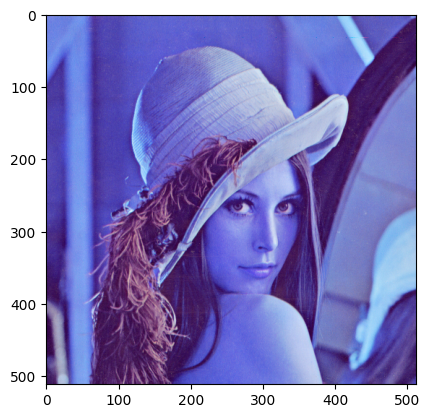

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

# %matplotlib inline allows Matplotlib plots to be displayed in Jupyter
plt.imshow(image[:,:,:])

By default, when an image file is read using the `cv.imread()` method, the image is stored in the BGR color space rather than RGB (which is more familiar), meaning that the color channels are in a different order. This causes the image to be displayed incorrectly by Matplotlib, because Matplotlib displays images in the RGB color space.

To convert the color space to RGB, you can use the following method:
`rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`

Let's convert our image:

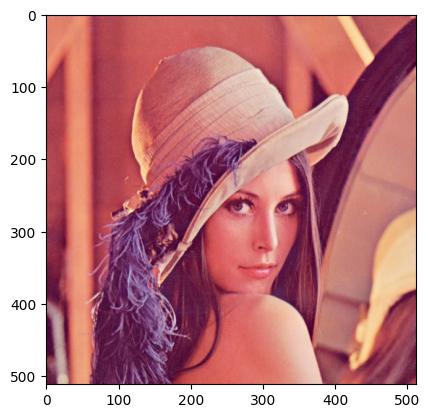

In [4]:
rgb_image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.imshow(rgb_image)

## 1.3. Basic Image Operations

### 1.3.1 Cropping or ROI
**Cropping** is the process of trimming an image to isolate an object of interest.

**ROI** (Region of Interest) refers to the image region containing the object of interest.

Since a color image is a three-dimensional NumPy array, it can be cropped using array slicing:

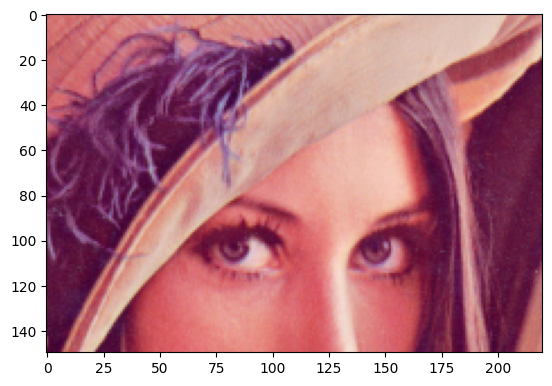

In [6]:
ROI = (182, 162, 220, 150)  #(x0, y0, height, width)
cropped_image = rgb_image[ROI[1]:ROI[1] + ROI[3], ROI[0]:ROI[0] + ROI[2]]
plt.imshow(cropped_image)

### 1.3.2 Resizing an Image

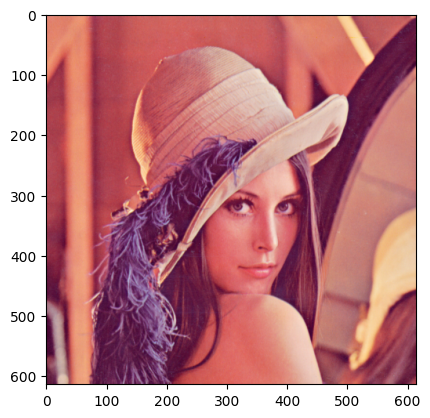

In [7]:
scale_percent = 120  # Percentage of the original size
width = int(rgb_image.shape[1] * scale_percent / 100)
height = int(rgb_image.shape[0] * scale_percent / 100)
dim = (width, height)
resized_image = cv.resize(rgb_image, dim, interpolation=cv.INTER_AREA)
plt.imshow(resized_image)

### 1.3.3 Image Rotation

Image rotation is one of the affine transformations. Other affine transformations include translation, shifting, and scaling: https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html. It is convenient to describe rotation using a transformation matrix. For more details, see the article [Transformation matrix — Wikipedia](https://en.wikipedia.org/wiki/Transformation_matrix).

In the case of rotation, the transformation matrix is calculated using the `cv.getRotationMatrix2D(center, angle, scale)` function, where `center` and `angle` are the center coordinates and rotation angle, respectively, and `scale` is the scaling factor. Information about image rotation and other geometric transformations is available in the [documentation](https://docs.opencv.org/3.4/da/d54/group__imgproc__transform.html).

[[   0.70710678    0.70710678 -106.03867197]
 [  -0.70710678    0.70710678  256.        ]]


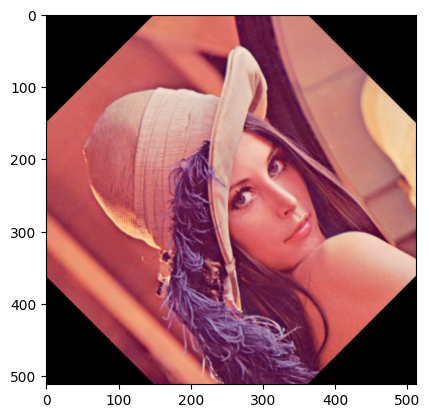

In [8]:
(h, w, d) = rgb_image.shape
angle = 45
scale = 1.0
center = (w // 2, h // 2)
M = cv.getRotationMatrix2D(center, angle, scale)

print(M)
rotated = cv.warpAffine(rgb_image, M, (w, h))
plt.imshow(rotated)

### 1.3.4 Drawing Shapes on an Image
- `cv.line(image, startPoint, endPoint, rgb_color, thickness)`
- `cv.rectangle(image, topLeft, bottomRight, rgb_color, thickness)`
- `cv.circle(image, center, radius, rgb_color, thickness)`
- `cv.ellipse(image, center, axes, angle, startAngle, endAngle, rgb_color, thickness)`

where:
- `image` -- the image;
- `startPoint`, `endPoint` -- coordinates of the starting and ending points;
- `rgb_color` -- color code in RGB format (red, green, blue), where red, green, blue ∈ [0, 255];
- `thickness` -- line thickness in pixels;
- `center` -- coordinates of the center of the circle or ellipse;
- `topLeft`, `bottomRight` -- coordinates of the top-left and bottom-right corners of the rectangle, respectively.

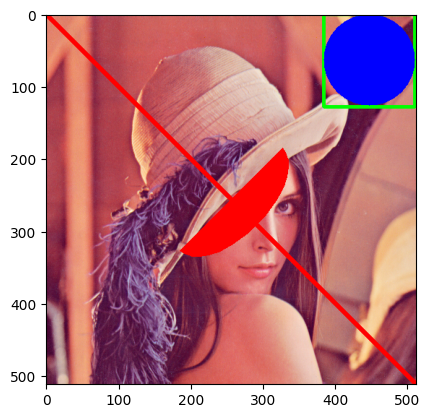

In [9]:
copy_image = rgb_image.copy()

# Draw a line
cv.line(copy_image, (0, 0), (511, 511), (255, 0, 0), 5)
# => Diagonal red line with thickness of 5 px

# Draw a rectangle using cv2.rectangle(image, topLeft, bottomRight, rgb, thinkness)
cv.rectangle(copy_image, (384, 0), (510, 128), (0, 255, 0), 3)
# => Green rectangle with thickness of 3 px

# Draw a circle using cv2.circle(image, center, radius, rgb, thinkness)
cv.circle(copy_image, (447, 63), 63, (0, 0, 255), -1)
# => Blue filled circle(note that the thinkness is -1)

# Draw a ellipse using cv2.ellipse(image, center, axes, angle, startAngle, endAngle, rgb, thinkness)
cv.ellipse(copy_image, (256, 256), (100, 50), -45, 0, 180, (255, 0, 0), -1)
# => Red wide down-half ellipse

plt.imshow(copy_image)

### 1.3.5 Adding Text to an Image

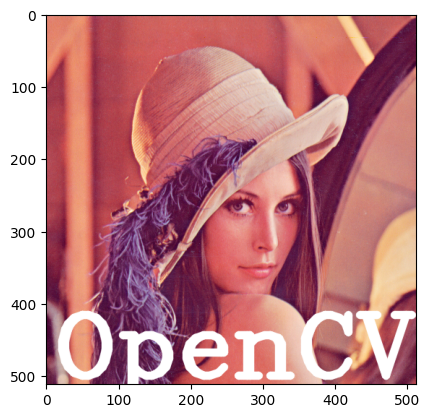

In [10]:
# Put some text using cv2.putText(image, text, bottomLeft, fontType, fontScale, rgb, thinkness, lineType)
copy_image = rgb_image.copy()
font = cv.FONT_HERSHEY_COMPLEX
cv.putText(copy_image, 'OpenCV', (10, 500), font, 4, (255, 255, 255), 10, cv.LINE_AA)
# => White 'OpenCV' text at the bottom

plt.imshow(copy_image)

# 2. Histogram Processing

## 2.1 Histogram-Based Image Processing

### 2.1.1 Building and Visualizing a Histogram
A histogram describes the frequency of pixels with the same intensity in an image and makes it possible to analyze the image's brightness component. A histogram can be used to assess and appropriately adjust image brightness and contrast, determine the proportions of bright, dark, and other intensity elements in the image, and identify where regions (objects) corresponding to particular intensity ranges are located in the image plane.

Read the OpenCV histogram documentation [here](https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html).

In [11]:
%reset

Once deleted, variables cannot be recovered. Proceed (y/[n])? y


In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import cv2 as cv
import numpy as np

# Change the default size of Matplotlib plots
plt.rcParams["figure.figsize"] = [6, 4]

/tmp/ipykernel_303/3442923812.py:22: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image1.reshape(-1), 256, range)
/tmp/ipykernel_303/3442923812.py:24: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image2.reshape(-1), 256, range)


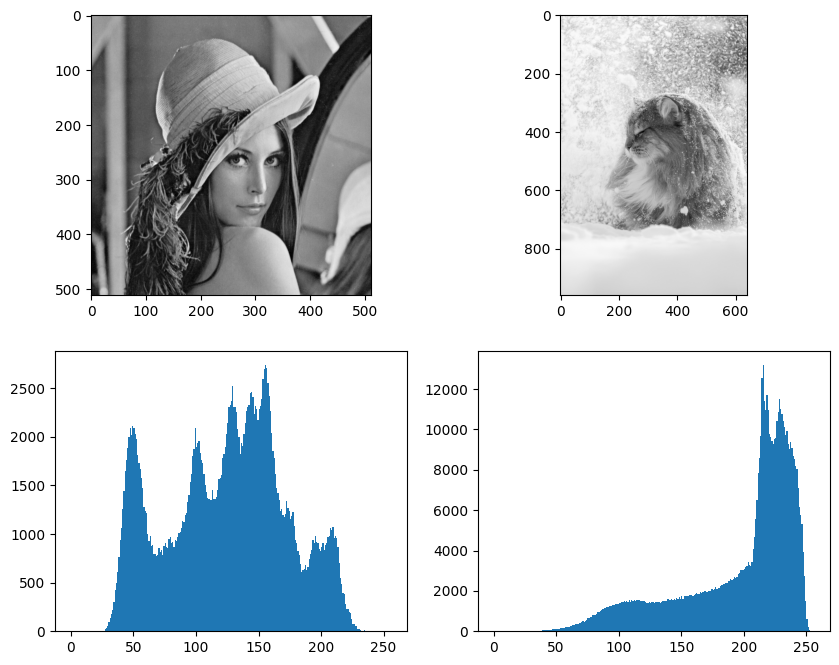

In [13]:
image1 = cv.imread('./lenna.png')
image2 = cv.imread('./winter_cat.png')
rgb_image1 = cv.cvtColor(image1, cv.COLOR_BGR2RGB)
rgb_image2 = cv.cvtColor(image2, cv.COLOR_BGR2RGB)
gray_image1 = cv.cvtColor(image1, cv.COLOR_BGR2GRAY)
gray_image2 = cv.cvtColor(image2, cv.COLOR_BGR2GRAY)

channels = [0]
histSize = [256]
range = [0, 256]

hist1 = cv.calcHist([gray_image1], channels, None, histSize, range)
hist2 = cv.calcHist([gray_image2], channels, None, histSize, range)

gs = plt.GridSpec(2, 2)
plt.figure(figsize=(10, 8))
plt.subplot(gs[0])
plt.imshow(gray_image1, cmap='gray')
plt.subplot(gs[1])
plt.imshow(gray_image2, cmap='gray')
plt.subplot(gs[2])
plt.hist(gray_image1.reshape(-1), 256, range)
plt.subplot(gs[3])
plt.hist(gray_image2.reshape(-1), 256, range)
plt.show()


Remember that this histogram is plotted for a grayscale image, not a color image. The left side of the histogram shows the number of darker pixels in the image, while the right side shows the number of brighter pixels. The first histogram indicates that pixel intensities are distributed fairly evenly, unlike the histogram of the second image, which contains predominantly bright pixels.

Other ways to visualize histograms:
1. Using Matplotlib

/tmp/ipykernel_303/4049604178.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image1.reshape(-1), 256, range)


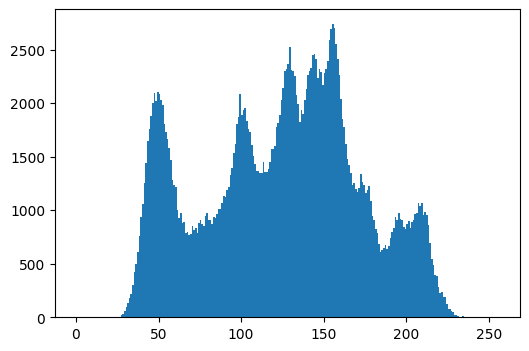

In [14]:
plt.hist(gray_image1.reshape(-1), 256, range)
plt.show()

2. OpenCV can also be used to visualize histograms for individual color channels.

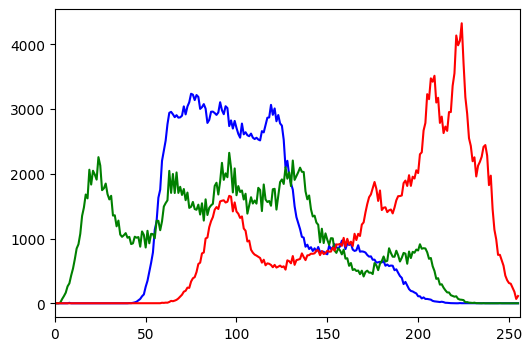

In [15]:
histSize = [256]
range = [0, 256]


def plot_rgb_hist(image, histSize, range):
    histSize = [256]
    range = [0, 256]
    for i, col in enumerate(['b', 'g', 'r']):
        hist = cv.calcHist([image], [i], None, histSize, range)
        plt.plot(hist, color=col)
        plt.xlim(range)


plot_rgb_hist(image1, histSize, range)
plt.show()

The plot shows that red is the dominant color.

### 2.1.2 Intensity (Histogram) Transformations
Intensity transformations of digital images are often called *histogram transformations* because, first, they change the image histogram and, second, the form of the transformation function (its parameters) is often determined *adaptively*, based on the histogram previously obtained from the original image.

For discrete digital images, the intensity mapping function takes the form of a so-called *look-up table* (**LUT**). Histogram processing using a look-up table is performed as follows:
$$
{\rm Im}[i,j] = {\rm LUT[Im}[i,j]],
$$
where Im$[i,j]$ is the pixel of the image at coordinates $\langle i,j \rangle$, and LUT is an integer array containing $256$ elements for an $8$-bit image or $65\,536$ elements for a $16$-bit image.

The LUT can be specified as:
- an arbitrary mapping table created directly by the user;
- a mathematical function selected from a predefined set of functions;
- an adaptive mapping based on the histogram of the image being analyzed.

Let's consider several examples. First, prepare a test image with slightly degraded quality (increased brightness and reduced contrast).

#### 2.1.2.1 Inversion
The simplest example of histogram-based image processing is *intensity inversion*, defined by the relationship
$$
{\rm LUT}[i] = 255 - i.
$$
The result of image inversion is its *negative*. Dark regions become bright, and vice versa.

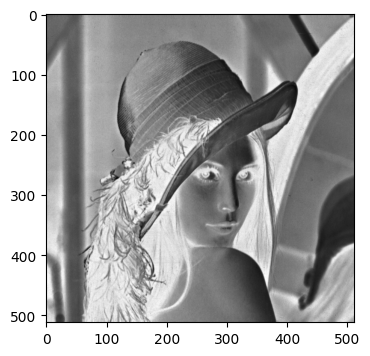

In [16]:
lut = lambda i: 255 - i
invert_image = lut(gray_image1)
plt.imshow(invert_image, cmap='gray')

#### 2.1.2.2 Gamma Correction
Gamma correction follows a power-law function of the form
$$
{\rm LUT}[i] = r(i)^{\gamma },
$$
where $r$ is the contrast coefficient and $\gamma$ is the exponent of the transformation.

Such transformations are known in analog television as the procedure of $\it{gamma correction}$. It is easy to see that by changing the parameter $\gamma$, we can obtain LUTs of different types. When $\gamma = 1$, the transformation is linear; when $\gamma < 1$, brighter colors are favored (they occupy a larger part of the range); when $\gamma > 1$, darker colors are favored. Such transformations are used to "equalize" the brightness of images displayed on cathode-ray tube (CRT) screens.

/tmp/ipykernel_303/1545475664.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image1.reshape(-1), 256, range)
/tmp/ipykernel_303/1545475664.py:15: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(result_image.reshape(-1), 256, range)


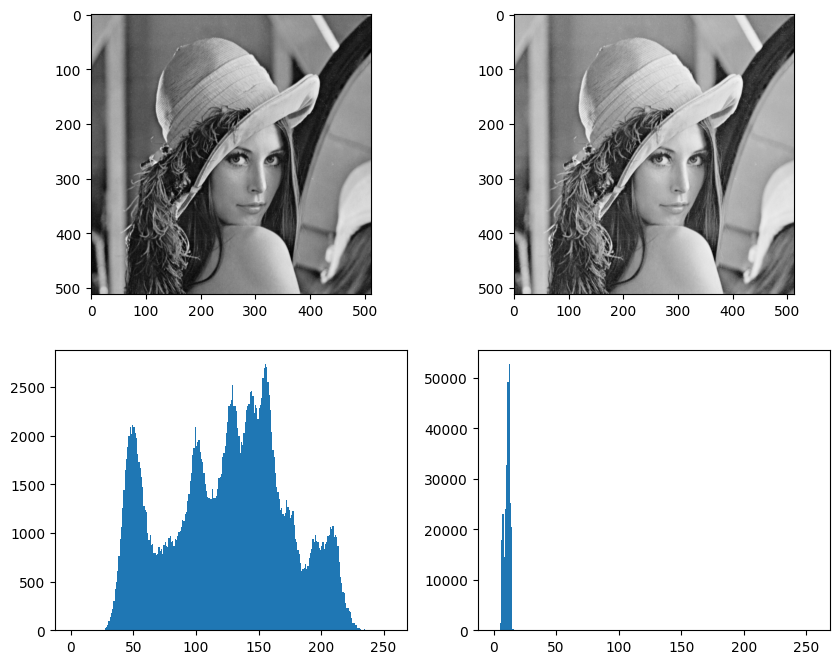

In [18]:
gamma = 0.5

lut = lambda i: i ** gamma
result_image = lut(gray_image1)
#print(result_image[1:2])
gs = plt.GridSpec(2, 2)
plt.figure(figsize=(10, 8))
plt.subplot(gs[0])
plt.imshow(gray_image1, cmap='gray')
plt.subplot(gs[1])
plt.imshow(result_image, cmap='gray')
plt.subplot(gs[2])
plt.hist(gray_image1.reshape(-1), 256, range)
plt.subplot(gs[3])
plt.hist(result_image.reshape(-1), 256, range)
plt.show()

#### 2.1.2.3 Adaptive Correction

Now let's consider a simple method of *adaptive* histogram processing (that is, a method whose parameters are not predefined but depend on the particular image).

##### 2.1.2.3.1 Intensity Normalization
We begin with a linear adaptive procedure called *image intensity normalization*, described by the following mathematical relationship:
$$
{\rm LUT}[i] = 255 \cdot  \frac {i - {I_{\min}}} {I_{\max} - I_{\min}}.
$$
$I_{\min} = \min\limits_{x,y} \textrm{Im} [x,y]$, $I_{\max} = \max\limits_{x, y} \textrm{Im} [x,y]$.

The values $I_{\min}$ and $I_{\max}$ are defined as the minimum and maximum indices of the non-zero bins in the histogram Hist(Im).

This transformation uniformly "stretches" the intensity range
[$I_{\min}, I_{\max}$] present in the original image Im
to the widest possible range $[0, 255]$. This helps improve image contrast as much as possible without losing any differences between the intensity levels in the original image.

/tmp/ipykernel_303/2048293815.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image2.reshape(-1), 256, range)
/tmp/ipykernel_303/2048293815.py:14: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(result_image.reshape(-1), 256, range)


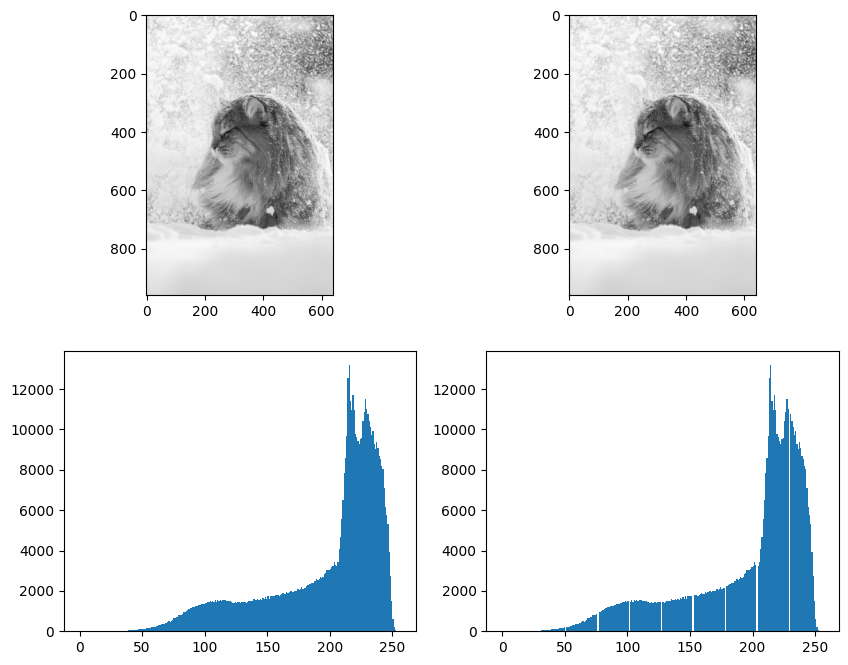

In [20]:
lut = lambda i: 255 * ((i - np.min(i)) / (np.max(i) - np.min(i)))
result_image = lut(gray_image2)
image2 = cv.imread('./winter_cat.png')

gs = plt.GridSpec(2, 2)
plt.figure(figsize=(10, 8))
plt.subplot(gs[0])
plt.imshow(gray_image2, cmap='gray')
plt.subplot(gs[1])
plt.imshow(result_image, cmap='gray')
plt.subplot(gs[2])
plt.hist(gray_image2.reshape(-1), 256, range)
plt.subplot(gs[3])
plt.hist(result_image.reshape(-1), 256, range)
plt.show()

##### 2.1.2.3.2 Histogram Equalization

Another popular adaptive histogram processing procedure is *histogram equalization*. Equalization also maps the actual intensity range of an image (from the minimum to the maximum intensity value) to the range [0, 255]. At the same time, it aims to equalize the number of image pixels with different intensity values. The mathematical form of this transformation is:
$$
{\rm LUT}[i] = 255 \cdot  \frac{\sum\limits_{j=1}^i \textrm{Hist}[j]} {\sum\limits_{j=1}^{255} \textrm{Hist}[j]},
$$
When all intensity levels in the range [Imin, Imax] are represented more or less uniformly, the visual effect of equalization is difficult to distinguish from that of normalization. However, when a significant number of intensity levels are absent, equalization makes it possible to use the range [0, 255] more uniformly, resulting in a higher-contrast representation of the intensity levels present in the image. Visually, this appears as the "revelation" of more details and contours that were previously difficult to see.

# **Assignment: Implement this type of histogram equalization yourself.**

#### Solution: my own histogram equalization

Steps:
1. Count how many pixels have each intensity 0..255 (the histogram `Hist`).
2. Take the running sum of the histogram (the cumulative histogram, CDF).
3. Divide by the total number of pixels and multiply by 255. This gives the LUT from the formula above.
4. Replace every pixel `i` with `LUT[i]`.

Left column: **Lenna**. Right column: **winter cat**.

In [ ]:
def my_equalize_hist(image):
    image = image.astype(np.uint8)
    # 1) Histogram: number of pixels for each intensity 0..255
    hist = np.bincount(image.ravel(), minlength=256)
    # 2) Cumulative histogram: sum of Hist[j] for j <= i
    cdf = np.cumsum(hist)
    # 3) LUT[i] = 255 * cdf[i] / (total number of pixels)
    lut = np.round(255 * cdf / cdf[-1]).astype(np.uint8)
    # 4) Apply the LUT to every pixel
    return lut[image]


eq_image1 = my_equalize_hist(gray_image1)  # Lenna
eq_image2 = my_equalize_hist(gray_image2)  # winter cat

fig, axes = plt.subplots(4, 2, figsize=(10, 16))
columns = [(gray_image1, eq_image1, 'Lenna'), (gray_image2, eq_image2, 'Winter cat')]
for col, (original, equalized, name) in enumerate(columns):
    axes[0, col].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(name + ' - original')
    axes[1, col].imshow(equalized, cmap='gray', vmin=0, vmax=255)
    axes[1, col].set_title(name + ' - equalized (my function)')
    axes[2, col].hist(original.reshape(-1), bins=256, range=(0, 256))
    axes[2, col].set_title(name + ' - original histogram')
    axes[3, col].hist(equalized.reshape(-1), bins=256, range=(0, 256))
    axes[3, col].set_title(name + ' - equalized histogram')
plt.tight_layout()
plt.show()

### 2.1.3 OpenCV CLAHE (Contrast Limited Adaptive Histogram Equalization)

OpenCV includes a built-in CLAHE method for histogram correction (equalization).

An OpenCV tutorial on histogram equalization is available [here](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html).

Let's consider an example of applying the CLAHE (Contrast Limited Adaptive Histogram Equalization) method:

In [40]:
import numpy as np

def my_clahe(image2, clip_limit=2.0, grid=(8, 8)):
  image2 = image2.astype(np.uint8)
  H, W = image2.shape
  gy, gx = grid
  # 1) Pad so the image splits evenly into tiles
  th, tw = -(-H // gy), -(-W // gx) # ceil division
  padded = np.pad(image2, ((0, th * gy - H), (0, tw * gx - W)), mode='reflect')
  n = th * tw # pixels per tile
  limit = max(int(clip_limit * n / 256), 1) # same formula as OpenCV

  # 2) One lookup table (LUT) per tile
  luts = np.zeros((gy, gx, 256), np.uint8)
  for i in np.arange(gy):
      for j in np.arange(gx):
          tile = padded[i*th:(i+1)*th, j*tw:(j+1)*tw]
          hist = np.bincount(tile.ravel(), minlength=256)
          # clip + redistribute the excess
          excess = np.sum(np.maximum(hist - limit, 0))
          hist = np.minimum(hist, limit)
          hist += excess // 256
          hist[:excess % 256] += 1
          # CDF -> new grey levels
          cdf = np.cumsum(hist)
          luts[i, j] = np.clip(np.round(cdf * 255 / n), 0, 255)

  # 3) Bilinear interpolation between the 4 nearest tiles
  y = (np.arange(H) + 0.5) / th - 0.5
  x = (np.arange(W) + 0.5) / tw - 0.5
  y0 = np.clip(np.floor(y).astype(int), 0, gy-1); y1 = np.clip(y0+1, 0, gy-1)
  x0 = np.clip(np.floor(x).astype(int), 0, gx-1); x1 = np.clip(x0+1, 0, gx-1)
  wy = np.clip(y - y0, 0, 1)[:, None]
  wx = np.clip(x - x0, 0, 1)[None, :]
  Y0, X0, Y1, X1 = y0[:, None], x0[None, :], y1[:, None], x1[None, :]

  tl = luts[Y0, X0, image2]; tr = luts[Y0, X1, image2]
  bl = luts[Y1, X0, image2]; br = luts[Y1, X1, image2]
  top = tl * (1 - wx) + tr * wx
  bot = bl * (1 - wx) + br * wx
  out = top * (1 - wy) + bot * wy
  return np.clip(np.round(out), 0, 255).astype(np.uint8)





In [41]:
rgb_result_image = np.empty(np.shape(rgb_image2), np.uint8)
for c in np.arange(3):
    rgb_result_image[:, :, c] = my_clahe(rgb_image2[:, :, c], 2.0, (8, 8))



In [ ]:
clahe_image1 = my_clahe(gray_image1, 2.0, (8, 8))  # Lenna
clahe_image2 = my_clahe(gray_image2, 2.0, (8, 8))  # winter cat

gs = plt.GridSpec(2, 2)
plt.figure(figsize=(10, 8))
plt.subplot(gs[0])
plt.imshow(clahe_image1, cmap='gray', vmin=0, vmax=255)
plt.title('Lenna')
plt.subplot(gs[1])
plt.imshow(clahe_image2, cmap='gray', vmin=0, vmax=255)
plt.title('Winter cat')
plt.subplot(gs[2])
plt.hist(clahe_image1.reshape(-1), bins=256, range=(0, 256))
plt.subplot(gs[3])
plt.hist(clahe_image2.reshape(-1), bins=256, range=(0, 256))
plt.show()

In [ ]:
rgb_result_image = np.empty(np.shape(rgb_image2), np.uint8)
for c in np.arange(3):
    rgb_result_image[:, :, c] = my_clahe(rgb_image2[:, :, c], 2.0, (8, 8))



In [ ]:
rgb_result_image = np.empty(np.shape(rgb_image2), np.uint8)
for c in np.arange(3):
    rgb_result_image[:, :, c] = my_clahe(rgb_image2[:, :, c], 2.0, (8, 8))

